In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/processed/criteo_uplift_v2.1.parquet")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA)
FEATURES = [f"f{i}" for i in range(12)]
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 13979592 entries, 0 to 13979591
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   f0          float32
 1   f1          float32
 2   f2          float32
 3   f3          float32
 4   f4          float32
 5   f5          float32
 6   f6          float32
 7   f7          float32
 8   f8          float32
 9   f9          float32
 10  f10         float32
 11  f11         float32
 12  treatment   int8   
 13  conversion  int8   
 14  visit       int8   
 15  exposure    int8   
dtypes: float32(12), int8(4)
memory usage: 693.3 MB


In [9]:
print("Anzahl fehlender Werte insgesamt:", df.isna().sum().sum())
print(df[FEATURES].nunique())          # Anzahl unterschiedlicher Werte je Feature
df[FEATURES].describe().T.round(3)

Anzahl fehlender Werte insgesamt: 0
f0     2181959
f1          60
f2      808663
f3         552
f4         260
f5         132
f6        1645
f7      622143
f8        3743
f9        1594
f10     483634
f11        136
dtype: int64


,count,mean,std,min,25%,50%,75%,max
f0,13979592.0,19.620,5.377,12.616,12.616,21.923,24.436,26.745
f1,13979592.0,10.070,0.105,10.060,10.060,10.060,10.060,16.344
f2,13979592.0,8.447,0.299,8.214,8.214,8.214,8.723,9.052
f3,13979592.0,4.179,1.337,-8.398,4.680,4.680,4.680,4.680
f4,13979592.0,10.339,0.343,10.281,10.281,10.281,10.281,21.124
f5,13979592.0,4.029,0.431,-9.012,4.115,4.115,4.115,4.115
f6,13979592.0,-4.155,4.578,-31.430,-6.699,-2.411,0.294,0.294
f7,13979592.0,5.102,1.205,4.834,4.834,4.834,4.834,11.998
f8,13979592.0,3.934,0.057,3.635,3.911,3.972,3.972,3.972
f9,13979592.0,16.028,7.019,13.190,13.190,13.190,13.190,75.295


In [3]:
g = df.groupby("treatment")
summary = pd.DataFrame({
    "n": g.size(),
    "share": g.size() / len(df),
    "visit_rate": g["visit"].mean(),
    "conversion_rate": g["conversion"].mean(),
    "exposure_rate": g["exposure"].mean(),
    "n_visits": g["visit"].sum(),
    "n_conversions": g["conversion"].sum(),
})
display(summary)

for y in ["visit", "conversion"]:
    t, c = summary.loc[1, f"{y}_rate"], summary.loc[0, f"{y}_rate"]
    print(f"{y}: treated {t:.4%} | control {c:.4%} | "
          f"diff {t - c:.4%} | relative lift {t / c - 1:.1%}")

,n,share,visit_rate,conversion_rate,exposure_rate,n_visits,n_conversions
treatment,,,,,,,
0,2096937,0.15,0.038201,0.001938,0.000000,80105,4063
1,11882655,0.85,0.048543,0.003089,0.036037,576824,36711


visit: treated 4.8543% | control 3.8201% | diff 1.0342% | relative lift 27.1%
conversion: treated 0.3089% | control 0.1938% | diff 0.1152% | relative lift 59.4%


In [10]:
treated = df[df.treatment == 1]
print("Expositionsrate in der Treatment-Gruppe (Compliance-Rate):", treated["exposure"].mean())
treated.groupby("exposure")[["visit", "conversion"]].mean()

Expositionsrate in der Treatment-Gruppe (Compliance-Rate): 0.036036727482199896


,visit,conversion
exposure,,
0,0.034861,0.001194
1,0.414538,0.053784


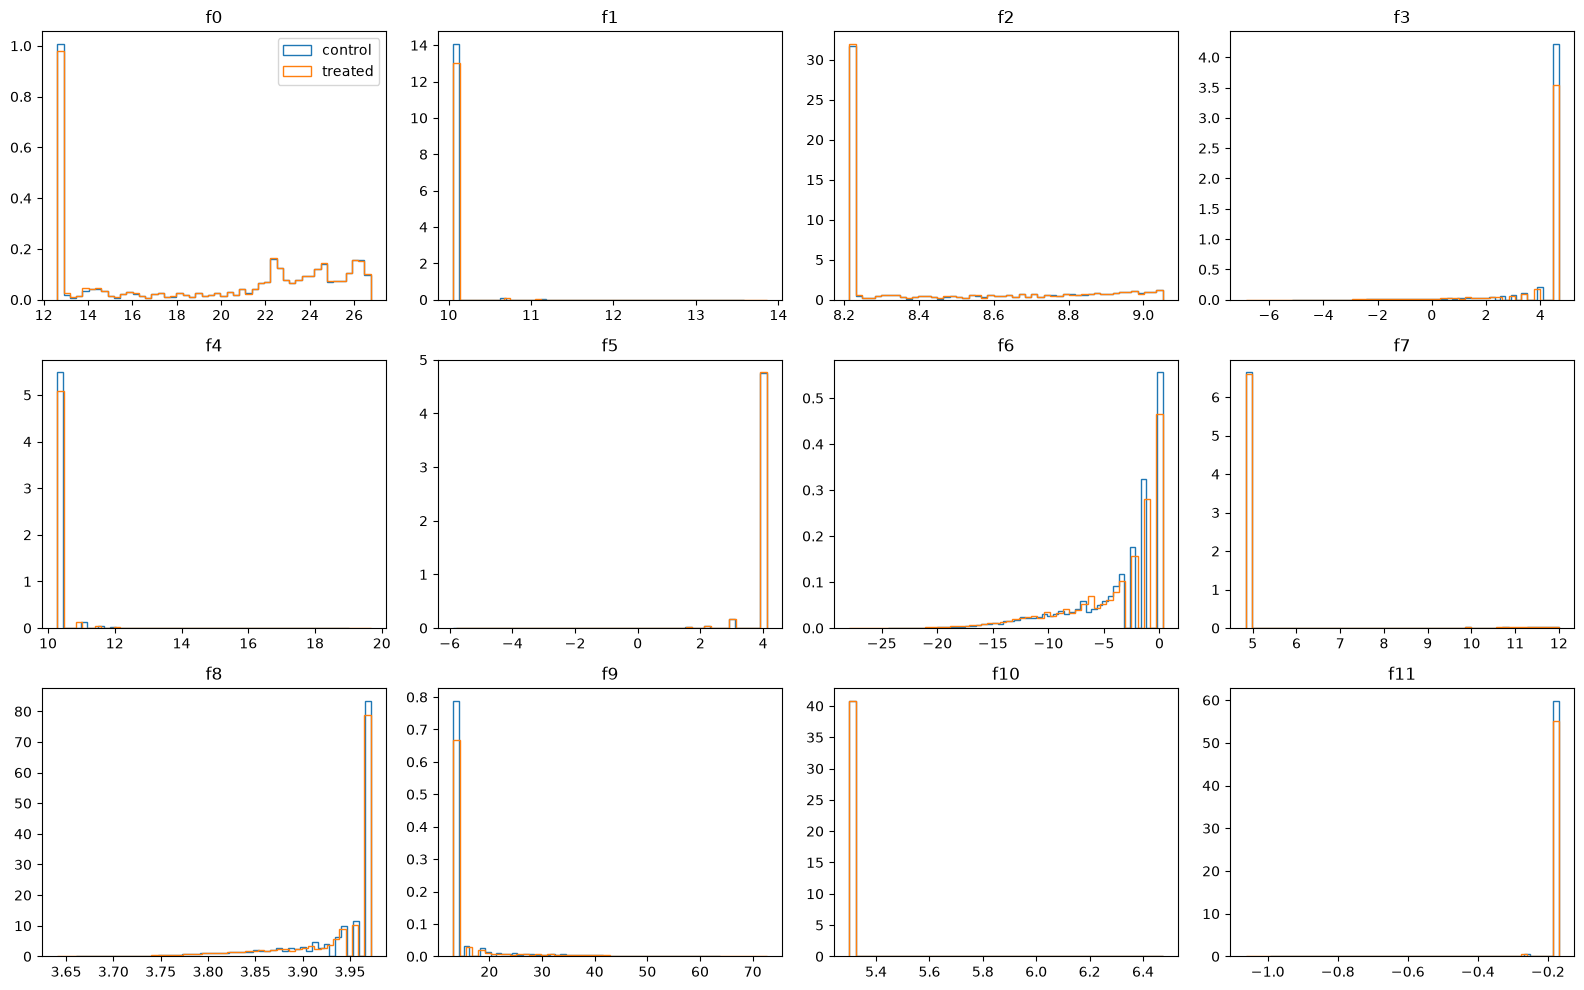

In [5]:
sample = df.sample(500_000, random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, f in zip(axes.ravel(), FEATURES):
    for t, label in [(0, "control"), (1, "treated")]:
        ax.hist(sample.loc[sample.treatment == t, f], bins=50,
                density=True, histtype="step", label=label)
    ax.set_title(f)
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG / "feature_dist_by_group.png", dpi=120)

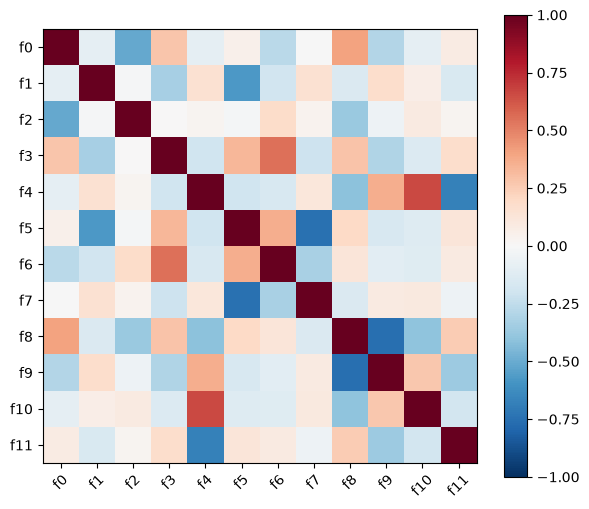

In [6]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(12), FEATURES, rotation=45)
ax.set_yticks(range(12), FEATURES)
fig.colorbar(im)
fig.savefig(FIG / "feature_corr.png", dpi=120)

In [7]:
def smd(x_t, x_c):
    return (x_t.mean() - x_c.mean()) / np.sqrt((x_t.var() + x_c.var()) / 2)

t = df[df.treatment == 1]
c = df[df.treatment == 0]
balance = pd.DataFrame({
    "mean_treated": t[FEATURES].mean(),
    "mean_control": c[FEATURES].mean(),
    "smd": [smd(t[f], c[f]) for f in FEATURES],
}).round(4)
balance["flag"] = balance["smd"].abs() > 0.1
balance

,mean_treated,mean_control,smd,flag
f0,19.614799,19.651699,-0.0069,False
f1,10.070300,10.067900,0.0240,False
f2,8.446300,8.448200,-0.0062,False
f3,4.169400,4.232800,-0.0488,False
f4,10.339200,10.336500,0.0080,False
f5,4.026600,4.039300,-0.0306,False
f6,-4.182800,-3.999900,-0.0404,False
f7,5.105600,5.080300,0.0213,False
f8,3.933400,3.934700,-0.0224,False
f9,16.052601,15.886300,0.0240,False


In [8]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

sub = df.sample(2_000_000, random_state=0)
X_tr, X_te, w_tr, w_te = train_test_split(
    sub[FEATURES], sub["treatment"], test_size=0.5,
    random_state=0, stratify=sub["treatment"])

clf = LGBMClassifier(n_estimators=200, learning_rate=0.05, verbose=-1)
clf.fit(X_tr, w_tr)
auc = roc_auc_score(w_te, clf.predict_proba(X_te)[:, 1])
print(f"AUC = {auc:.4f}")

AUC = 0.5101


## Findings
- Stichprobe: N = 13979592, Anteil der Treatment-Gruppe 0.85
- Visit: Treatment 4.8543% vs. Kontrolle 3.8201% (relativer Lift 27.1%)
- Conversion: Treatment 0.3089% vs. Kontrolle 0.1938%; nur 4063 Conversions in der Kontrollgruppe
- Expositionsrate in der Treatment-Gruppe: 0.036; Maximum von exposure in der Kontrollgruppe: 0
- Balance: maximales |SMD| = 0.0488; Klassifikator-AUC = 0.5101
- Fazit: Die Randomisierung hält